# Deep Learning - Assignment 2
### Training-Testing CNN with CIFAR Dataset using PyTorch
#### Group No. 5

#### Setup

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"  # fixes the OpenMP error with Anaconda on Windows

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# Use the GPU if available, otherwise the CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu128
Device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


#### Task 1

In [2]:
# Directory where the dataset will be downloaded
DATA_PATH = "./data"

# CIFAR-10 class names
classes = ("plane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")

# Basic transform: convert to tensor and normalize each RGB channel
# (mean and std of the CIFAR-10 training set)
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2470, 0.2435, 0.2616)

basic_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

# Download and load CIFAR-10
train_set = torchvision.datasets.CIFAR10(root=DATA_PATH, train=True,  download=True, transform=basic_transform)
test_set  = torchvision.datasets.CIFAR10(root=DATA_PATH, train=False, download=True, transform=basic_transform)

# DataLoaders
batch_size = 64
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True,  num_workers=0)
test_loader  = DataLoader(test_set,  batch_size=batch_size, shuffle=False, num_workers=0)

print("Dataset loaded successfully!")
print("Training images:", len(train_set))
print("Test images:    ", len(test_set))
print("Classes:", classes)

100%|██████████| 170M/170M [31:13<00:00, 91.0kB/s]   


Dataset loaded successfully!
Training images: 50000
Test images:     10000
Classes: ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')


#### Task 2

In [3]:
class CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding)
        # Block 1: 3 x 32 x 32 -> 32 x 16 x 16
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1)
        # Block 2: 32 x 16 x 16 -> 64 x 8 x 8
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        # Block 3: 64 x 8 x 8 -> 128 x 4 x 4
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)

        # Max pooling halves the height and width
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.relu = nn.ReLU()

        # Classifier
        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.dropout = nn.Dropout(0.5)  # randomly drops neurons to reduce overfitting
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        # Feature extraction
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        # Classification
        x = torch.flatten(x, 1)          # (N, 128, 4, 4) -> (N, 2048)
        x = self.dropout(self.relu(self.fc1(x)))
        x = self.fc2(x)                  # no softmax: CrossEntropyLoss applies it
        return x

model = CNN().to(device)  # move the network to the GPU (or CPU)
print(model)

# Verify the shapes with one batch
images, labels = next(iter(train_loader))
images = images.to(device)
print("\nInput shape: ", images.shape)
print("Output shape:", model(images).shape)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (fc1): Linear(in_features=2048, out_features=256, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)

Input shape:  torch.Size([64, 3, 32, 32])
Output shape: torch.Size([64, 10])
Trainable parameters: 620362


In [4]:
def train(net, dataloader, optimizer, criterion):
    """Train the network for one epoch. Returns the average loss and accuracy."""
    net.train()  # training mode (dropout is active)
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()              # 1. clear old gradients
        outputs = net(images)              # 2. forward pass
        loss = criterion(outputs, labels)  # 3. compute the loss
        loss.backward()                    # 4. backpropagation
        optimizer.step()                   # 5. update the weights

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, 100 * correct / total

In [5]:
def test(net, dataloader, criterion):
    """Evaluate the network. Returns the average loss and accuracy."""
    net.eval()  # evaluation mode (dropout is turned off)
    total_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():  # no gradients needed for testing
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = net(images)
            total_loss += criterion(outputs, labels).item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100 * correct / total

#### Task 3

In [6]:
# Get one batch from the training DataLoader
images, labels = next(iter(train_loader))

print("Images tensor size:", images.shape)
print("Labels tensor size:", labels.shape)
print("Single image size: ", images[0].shape)
print("Pixel value range after normalization: min = {:.2f}, max = {:.2f}".format(
    images.min().item(), images.max().item()))

Images tensor size: torch.Size([64, 3, 32, 32])
Labels tensor size: torch.Size([64])
Single image size:  torch.Size([3, 32, 32])
Pixel value range after normalization: min = -1.99, max = 2.13


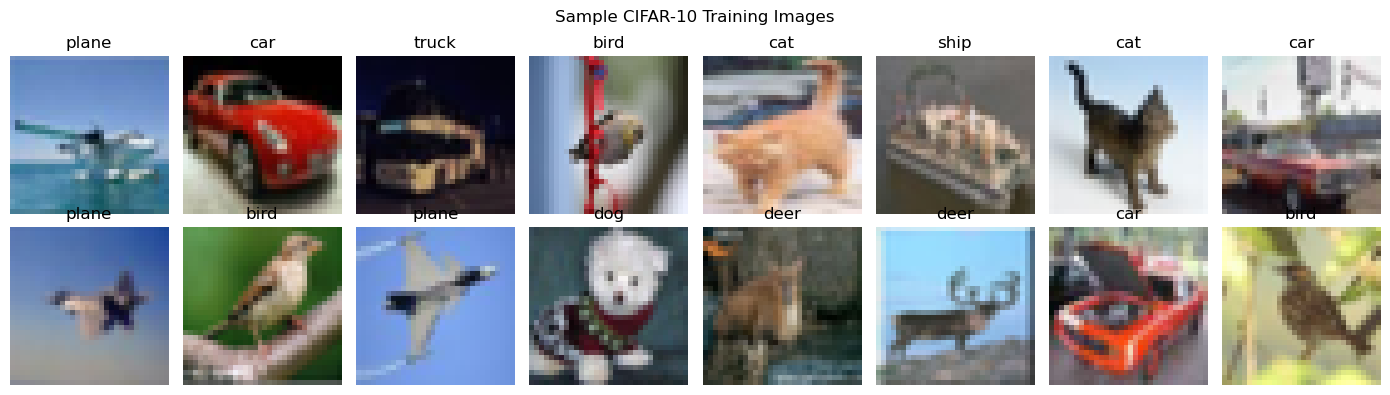

In [7]:
def imshow(img):
    """Undo the normalization and convert a tensor (C, H, W) to an image (H, W, C)."""
    mean = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
    std = torch.tensor(CIFAR_STD).view(3, 1, 1)
    img = img * std + mean                 # undo normalization
    img = img.clamp(0, 1)                  # keep values between 0 and 1
    return img.permute(1, 2, 0).numpy()    # (C, H, W) -> (H, W, C) for matplotlib

# Show the first 16 images in the batch with their class names
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(imshow(images[i]))
    ax.set_title(classes[labels[i].item()])
    ax.axis("off")

plt.suptitle("Sample CIFAR-10 Training Images")
plt.tight_layout()
plt.show()

#### Task 4

In [8]:
class AddGaussianNoise:
    """Adds random Gaussian noise to a tensor image (values in [0, 1])."""
    def __init__(self, std=0.05):
        self.std = std

    def __call__(self, img):
        noisy = img + torch.randn_like(img) * self.std
        return noisy.clamp(0, 1)

    def __repr__(self):
        return f"AddGaussianNoise(std={self.std})"


class AddSaltPepperNoise:
    """Sets a random fraction of pixels to black (pepper) or white (salt)."""
    def __init__(self, amount=0.02):
        self.amount = amount

    def __call__(self, img):
        img = img.clone()
        mask = torch.rand(img.shape[1:])            # one random value per pixel
        img[:, mask < self.amount / 2] = 0.0        # pepper (black)
        img[:, mask > 1 - self.amount / 2] = 1.0    # salt (white)
        return img

    def __repr__(self):
        return f"AddSaltPepperNoise(amount={self.amount})"

In [9]:
from torch.utils.data import Dataset

# Training transform with all the suggested augmentations
train_transform = transforms.Compose([
    transforms.ToPILImage(),                                    # 1. numpy array -> PIL image
    transforms.RandomResizedCrop(32, scale=(0.8, 1.0)),         # 3. random crop, resized back to 32x32
    transforms.RandomHorizontalFlip(p=0.5),                     # 2. flip left-right
    transforms.RandomRotation(degrees=10),                      # 5. rotate up to +/- 10 degrees
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),           # 4. change colors slightly
    transforms.ToTensor(),                                      # 8. PIL image -> tensor (C x H x W)
    transforms.RandomApply([AddGaussianNoise(std=0.05)], p=0.3),    # 7. noise (type 1)
    transforms.RandomApply([AddSaltPepperNoise(amount=0.02)], p=0.2), # 7. noise (type 2)
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),                # 6. normalize
])

# Test transform: NO random augmentation or noise, only the same normalization
test_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])


class CIFARFromArray(Dataset):
    """Wraps the raw CIFAR-10 numpy images so ToPILImage can be the first transform."""
    def __init__(self, data, targets, transform):
        self.data, self.targets, self.transform = data, targets, transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.transform(self.data[idx]), self.targets[idx]


# Raw datasets (already downloaded in Task 1, so no download happens here)
raw_train = torchvision.datasets.CIFAR10(root=DATA_PATH, train=True,  download=False)
raw_test  = torchvision.datasets.CIFAR10(root=DATA_PATH, train=False, download=False)

train_set_aug = CIFARFromArray(raw_train.data, raw_train.targets, train_transform)
test_set_aug  = CIFARFromArray(raw_test.data,  raw_test.targets,  test_transform)

train_loader_aug = DataLoader(train_set_aug, batch_size=batch_size, shuffle=True,  num_workers=0)
test_loader_aug  = DataLoader(test_set_aug,  batch_size=batch_size, shuffle=False, num_workers=0)

print("Training transform:\n", train_transform)
print("\nTest transform:\n", test_transform)
print("\nAugmented training images:", len(train_set_aug))
print("Test images:", len(test_set_aug))

Training transform:
 Compose(
    ToPILImage()
    RandomResizedCrop(size=(32, 32), scale=(0.8, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=(-0.05, 0.05))
    ToTensor()
    RandomApply(
    p=0.3
    AddGaussianNoise(std=0.05)
)
    RandomApply(
    p=0.2
    AddSaltPepperNoise(amount=0.02)
)
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)

Test transform:
 Compose(
    ToPILImage()
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)

Augmented training images: 50000
Test images: 10000


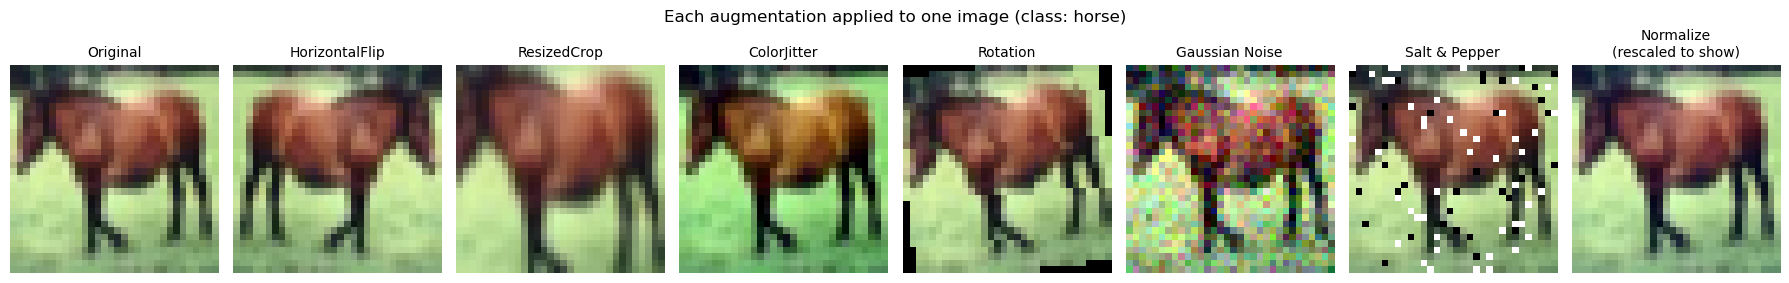

In [10]:
# Apply each augmentation separately to the same image
idx = 7
pil_img = transforms.ToPILImage()(raw_train.data[idx])
tensor_img = transforms.ToTensor()(pil_img)

normalized = transforms.Normalize(CIFAR_MEAN, CIFAR_STD)(tensor_img)
normalized_display = (normalized - normalized.min()) / (normalized.max() - normalized.min())

examples = {
    "Original": tensor_img,
    "HorizontalFlip": transforms.ToTensor()(transforms.RandomHorizontalFlip(p=1.0)(pil_img)),
    "ResizedCrop": transforms.ToTensor()(transforms.RandomResizedCrop(32, scale=(0.5, 0.7))(pil_img)),
    "ColorJitter": transforms.ToTensor()(transforms.ColorJitter(0.5, 0.5, 0.5, 0.1)(pil_img)),
    "Rotation": transforms.ToTensor()(transforms.RandomRotation(30)(pil_img)),
    "Gaussian Noise": AddGaussianNoise(std=0.1)(tensor_img),
    "Salt & Pepper": AddSaltPepperNoise(amount=0.08)(tensor_img),
    "Normalize\n(rescaled to show)": normalized_display,
}

fig, axes = plt.subplots(1, len(examples), figsize=(18, 3))
for ax, (name, img) in zip(axes, examples.items()):
    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.set_title(name, fontsize=10)
    ax.axis("off")
plt.suptitle(f"Each augmentation applied to one image (class: {classes[raw_train.targets[idx]]})")
plt.tight_layout()
plt.show()

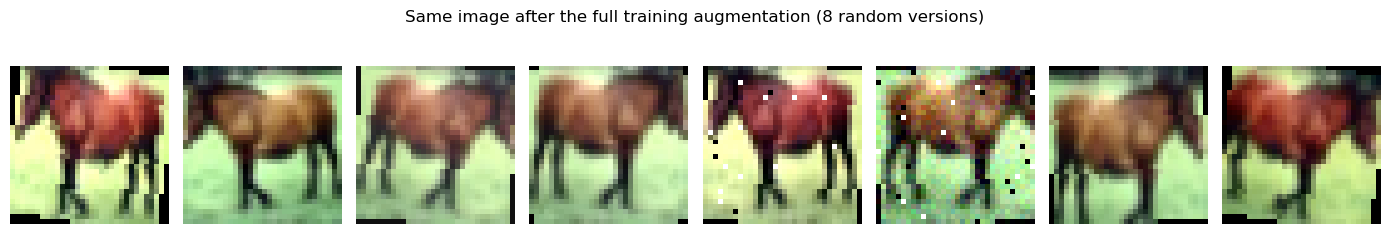

In [11]:
# Show the same image 8 times through the full random training transform
fig, axes = plt.subplots(1, 8, figsize=(14, 2.5))
for ax in axes:
    aug_img, _ = train_set_aug[idx]   # a different random version each time
    ax.imshow(imshow(aug_img))        # imshow() from Task 3 undoes the normalization
    ax.axis("off")
plt.suptitle("Same image after the full training augmentation (8 random versions)")
plt.tight_layout()
plt.show()